In [1]:
import numpy as np
import pandas as pd
from scipy import interpolate

import xarray as xr
import dask.array as da
from dask.distributed import Client

import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches # for creating legend
import matplotlib.dates as mdates # converts datetime64 to datetime

import cartopy
import cartopy.crs as ccrs # for plotting
import cartopy.feature as cfeature # for map features
from cartopy.util import add_cyclic_point # for wrapping map fully - avoiding white line on 0 deg
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter

import matplotlib.dates as mdates # converts datetime64 to datetime
import matplotlib.gridspec as gridspec # to create grid-shaped combos of axes
from mpl_toolkits import mplot3d # 3d plotting tool
import cmocean # for nice oceanography colour pallettes

#import argopy
#from argopy import DataFetcher as ArgoDataFetcher # to load Argo ds directly

import os # for finding files

import gsw # for conversion functions

from tqdm.notebook import tqdm_notebook as tqdm
import glob # for downloading data
import sys # for path to functions

import seaborn as sns

sns.set(#font='Helvetica',
        rc={
         'axes.axisbelow': False,
         'axes.edgecolor': 'Black',
         'axes.facecolor': 'w', 
                            # '#aeaeae',
         'axes.grid': False,
         'axes.labelcolor': 'k',
         'axes.spines.right': True,
         'axes.spines.top': True,
         'figure.facecolor': 'white',
         'lines.solid_capstyle': 'round',
         'patch.edgecolor': 'k',
         'patch.force_edgecolor': True,
         'text.color': 'k',
         'xtick.bottom': True,
         'xtick.color': 'k',
         'xtick.direction': 'out',
         'xtick.top': False,
         'ytick.color': 'k',
         'ytick.direction': 'out',
         'ytick.left': True,
         'ytick.right': False},
         font_scale=1)
mpl.rcParams["figure.titlesize"] = 25
mpl.rcParams["axes.titlesize"] = 22
mpl.rcParams["axes.labelsize"] = 20
mpl.rcParams["font.size"] = 18
mpl.rcParams["xtick.labelsize"] = 18
mpl.rcParams["ytick.labelsize"] = 18
mpl.rcParams["ytick.labelright"] = False

from warnings import filterwarnings as fw
fw('ignore')

# import my own funcs
import sys
sys.path.append('/home/theospira/notebooks/projects/01-WW_climatology/functions')
from plot_formatting import circular_boundary,plot_nice_box
from inspection_funcs import boxplot

import importlib
#importlib.reload(sys.modules['inspection_plot'])

In [2]:
from matplotlib.dates import AutoDateLocator

sys.path.append('/home/theospira/notebooks/projects/03-WW-timeseries/funcs')
from plotting import *
from computations import *
from import_data import *
from smoothing_and_interp import wrap_smth_var,nan_interp

In [3]:
cmap_br = get_cmap()
from plot_formatting import plot_gridlines
from smoothing_and_interp import wrap_smth_var,nan_interp

In [4]:
sys.path.append('/home/theospira/notebooks/projects/05-WW_sea_ice_regionality/functions')
from plotting_v5 import *

In [5]:
from computations import polyfit_xr

t_slice_p1 = slice(np.datetime64('2005-01-01'),np.datetime64('2015-08-31'))
t_slice_p2 = slice(np.datetime64('2015-09-01'),np.datetime64('2025-01-01'))

def calc_trend_per_gc(dsvar, t_slice=slice(np.datetime64('2000-01-01'), np.datetime64('2015-08-31'))):
    """
    Calculate the linear trend per grid cell (gc) from an xarray DataArray.
    
    Parameters:
    - dsvar: xarray DataArray with dimensions including 'time'
    - t_slice: optional time range (as slice of np.datetime64)

    Returns:
    - trend: linear trend per year for each grid cell
    - n: number of valid time samples per grid cell
    """

    if t_slice is not None:
        dsvar = dsvar.sel(time=t_slice)

    # Perform linear regression
    s1, i1 = polyfit_xr(dsvar)

    # Count valid values (NaNs ignored)
    n = dsvar.notnull().sum('time').where(dsvar.mean('time').notnull())

    time_num_xr = xr.DataArray(pd.to_numeric(dsvar.time.values), dims='time', coords={'time': dsvar['time']})

    y = time_num_xr * s1 + i1
    trend = ((y[-1] - y[0]) / time_num_xr.size)

    # Count valid values (NaNs ignored)
    n = dsvar.notnull().sum('time').where(dsvar.mean('time').notnull())

    return trend, n

In [6]:
def rolling_var(dvar, x='lon', y='lat', t='time', nx=3, ny=3, mp=None, lon_wrap=False, x_wrap=20):
    """
    Apply rolling mean in space (lon/lat) with optional longitude wrapping.
    
    Parameters:
    - dvar: xarray DataArray with dimensions (..., lon, lat)
    - nx, ny: rolling window sizes in x and y directions. If ny is None, 0, or 1, skip y-direction rolling.
    - mp: minimum number of valid points to compute mean
    - lon_wrap: whether to wrap around longitude (cyclic)
    - x_wrap: number of points to wrap on each side if lon_wrap=True
    - t: name of time dimension, or None to ignore time
    
    Returns:
    - rolled_var: smoothed DataArray with same shape as original (minus wrap edges if used)
    """
    if t is not None:
        dvar = dvar.transpose(t, x, y)
    else:
        dvar = dvar.transpose(x, y)

    # Interpolate missing values for smoother rolling
    var = dvar.interpolate_na(dim=x, method='linear')
    if ny not in [None, 0, 1]:
        var = var.interpolate_na(dim=y, method='linear')

    # Add cyclic wrapping if requested
    if lon_wrap:
        wrap_start = var.isel({x: slice(-x_wrap, None)})
        wrap_end = var.isel({x: slice(0, x_wrap)})
        var = xr.concat([wrap_start, var, wrap_end], dim=x)

    # Setup rolling dims
    roll_dims = {x: nx}
    if ny not in [None, 0, 1]:
        roll_dims[y] = ny

    # Apply rolling mean
    rolled = var.rolling(roll_dims, min_periods=mp, center=True).mean(skipna=True)

    # Remove wrapped edge if wrapping was applied
    if lon_wrap:
        rolled = rolled.isel({x: slice(x_wrap, var.sizes[x] - x_wrap)})

    return rolled


In [7]:
from scipy.signal import gaussian

def gaussian_rolling(dvar, x='lon', y='lat', nx=3, ny=3, sigma_x=1.0, sigma_y=1.0, mp=None, lon_wrap=True, x_wrap=20, t=None):
    """
    Apply Gaussian-weighted rolling in space (lon/lat) with optional longitude wrapping.
    Missing values (NaNs) in the original data are reinserted after smoothing.

    Parameters:
    - dvar: xarray DataArray with lon/lat (and optional time) dimensions
    - nx, ny: size of rolling window
    - sigma_x, sigma_y: std dev for Gaussian kernel along x and y
    - mp: min_periods (optional, passed to .rolling)
    - lon_wrap: whether to wrap around longitude
    - x_wrap: number of points to wrap on each side
    - t: name of time dim if present (optional)

    Returns:
    - Smoothed DataArray with NaNs restored
    """
    # Store original NaN mask
    nan_mask = dvar.isnull()

    # Interpolate missing data
    var = dvar.copy()
    var = var.interpolate_na(dim=x, method='linear')
    if ny not in [None, 0, 1]:
        var = var.interpolate_na(dim=y, method='linear')

    # Apply longitude wrapping
    if lon_wrap:
        wrap_start = var.isel({x: slice(-x_wrap, None)})
        wrap_end = var.isel({x: slice(0, x_wrap)})
        var = xr.concat([wrap_start, var, wrap_end], dim=x)

    # Rolling window
    roll_kwargs = {x: nx}
    if ny not in [None, 0, 1]:
        roll_kwargs[y] = ny

    rolling_obj = var.rolling(roll_kwargs, center=True, min_periods=mp)

    # Construct window dimensions
    window_dims = {x: f'{x}_window'}
    if ny not in [None, 0, 1]:
        window_dims[y] = f'{y}_window'
    constructed = rolling_obj.construct(window_dim=window_dims)

    # Build Gaussian kernel
    wx = gaussian(nx, std=sigma_x)
    wy = gaussian(ny, std=sigma_y) if ny not in [None, 0, 1] else np.array([1.0])
    kernel = np.outer(wx, wy)
    kernel /= kernel.sum()

    # Apply kernel weights
    dims_to_sum = list(window_dims.values())
    weighted = constructed * kernel
    rolled = weighted.sum(dim=dims_to_sum)

    # Remove wrapping if needed
    if lon_wrap:
        rolled = rolled.isel({x: slice(x_wrap, var.sizes[x] - x_wrap)})

    # Restore NaNs from original
    rolled = rolled.where(~nan_mask)

    return rolled


In [8]:
def masked_dataset(ds,vars):
    """
    Mask the dataset for the specified variables and compute their anomalies.
    
    Parameters:
    - ds: xarray Dataset
    - vars: list of variable names to process

    Returns:
    - tmp: xarray Dataset with masked variables and their anomalies
    """
    # mask data and compute mixed layer anomalies
    tmp = ds[['ww_ct']+vars].copy()
    for i in tqdm(vars):
        tmp[i] = wrap_smth_var(tmp[i],t='time')
        tmp[i] = nan_interp(tmp[i])
    # mask data and compute mixed layer anomalies
    tmp = mask_data(ds,vars=['ww_ct']+vars)
    for v in vars:
        tmp = calc_mean_var(tmp,v)
        tmp[v+'_anm'] = tmp[v]-tmp[v+'_mn']
    
    return tmp

In [9]:
def plot_circumpolar_mean(ds,var):
    """
    Plot the circumpolar mean and anomaly of a variable over time.
    """

    fig,ax = plt.subplots(2,1,figsize=(15,10),sharex=True)

    print('Absolute lin reg slope rates')
    dsvar = ds[var]
    dsvar.mean(('lat','lon')).plot(x='time',ax=ax[0],lw=3)
    plot_lin_reg(dsvar,ax[0],date=np.datetime64('2015-08-31'),return_slope_rate=1)

    print('\n')
    print('Anomaly lin reg slope rates')

    dsvar = ds[var+'_anm']
    dsvar.mean(('lat','lon')).plot(x='time',ax=ax[1],marker='x',lw=3)
    plot_lin_reg(dsvar,ax[1],date=np.datetime64('2015-08-31'),return_slope_rate=1)

    for a in ax:
        si_timeseries_plot_formatting(a)

    a.axhline(0,ls='--',c='darkgrey',lw=2,zorder=0)

    fig.tight_layout()

# load data

In [10]:
# load sea ice data
si = load_sea_ice()
si = si.sel(lat=slice(-80,-52)).sel(time=slice('2005-01-01','2022-01-01'))
si = calc_mean_var(si,'sia')
si = calc_mean_var(si,'sic')
si['sia_anm'] = si.sia - si.sia_mn

In [11]:
d_path='/home/theospira/notebooks/projects/03-WW-timeseries/data/hydrographic_profiles/'
ds = xr.open_dataset(d_path+'gridded-timeseries-ww-recalc1.nc')

#tmp = mask_data(ds,vars=['ww_ct','ml_s','ml_t','mlp'])

# plots

In [12]:
vars = ['mlp','thcc','lw_bd','up_bd',]
tmp = masked_dataset(ds,vars)

  0%|          | 0/4 [00:00<?, ?it/s]

contains ww_ct


In [13]:
sns.set(#font='Helvetica',
        rc={
         'axes.axisbelow': False,
         'axes.edgecolor': 'Black',
         'axes.facecolor': 'w', 
                            # '#aeaeae',
         'axes.grid': False,
         'axes.labelcolor': 'k',
         'axes.spines.right': True,
         'axes.spines.top': True,
         'figure.facecolor': 'white',
         'lines.solid_capstyle': 'round',
         'patch.edgecolor': 'k',
         'patch.force_edgecolor': True,
         'text.color': 'k',
         'xtick.bottom': True,
         'xtick.color': 'k',
         'xtick.direction': 'out',
         'xtick.top': False,
         'ytick.color': 'k',
         'ytick.direction': 'out',
         'ytick.left': True,
         'ytick.right': False},
         font_scale=1)
mpl.rcParams["figure.titlesize"] = 20
mpl.rcParams["axes.titlesize"] = 20
mpl.rcParams["axes.labelsize"] = 16
mpl.rcParams["font.size"] = 18
mpl.rcParams["xtick.labelsize"] = 16
mpl.rcParams["ytick.labelsize"] = 16
mpl.rcParams["ytick.labelright"] = False


In [14]:
importlib.reload(sys.modules['computations'])
from computations import *

In [15]:
compute_correlation(si.sia.sel(time=t_slice_p1).mean(('time','lat')),si.sia.sel(time=t_slice_p2).mean(('time','lat')))

(0.9919427017295606, 3e-323)

/home/theospira/sw/miniconda3/envs/ww-env/lib/python3.11/site-packages/xarray/core/nputils.py:247: RankWarning: Polyfit may be poorly conditioned
  warn_on_deficient_rank(rank, x.shape[1])


Figure saved as: /home/theospira/notebooks/projects/03-WW-timeseries/figs/NCC-rev1/CDW_trend_SIA_corr.svg  💾
correlation between SIA´ p1 and trend: -0.44016217958811027  p-value: 0.007221473053640182
correlation between SIA´ p2 and trend: 0.4401621795881106  p-value: 0.007221473053640182


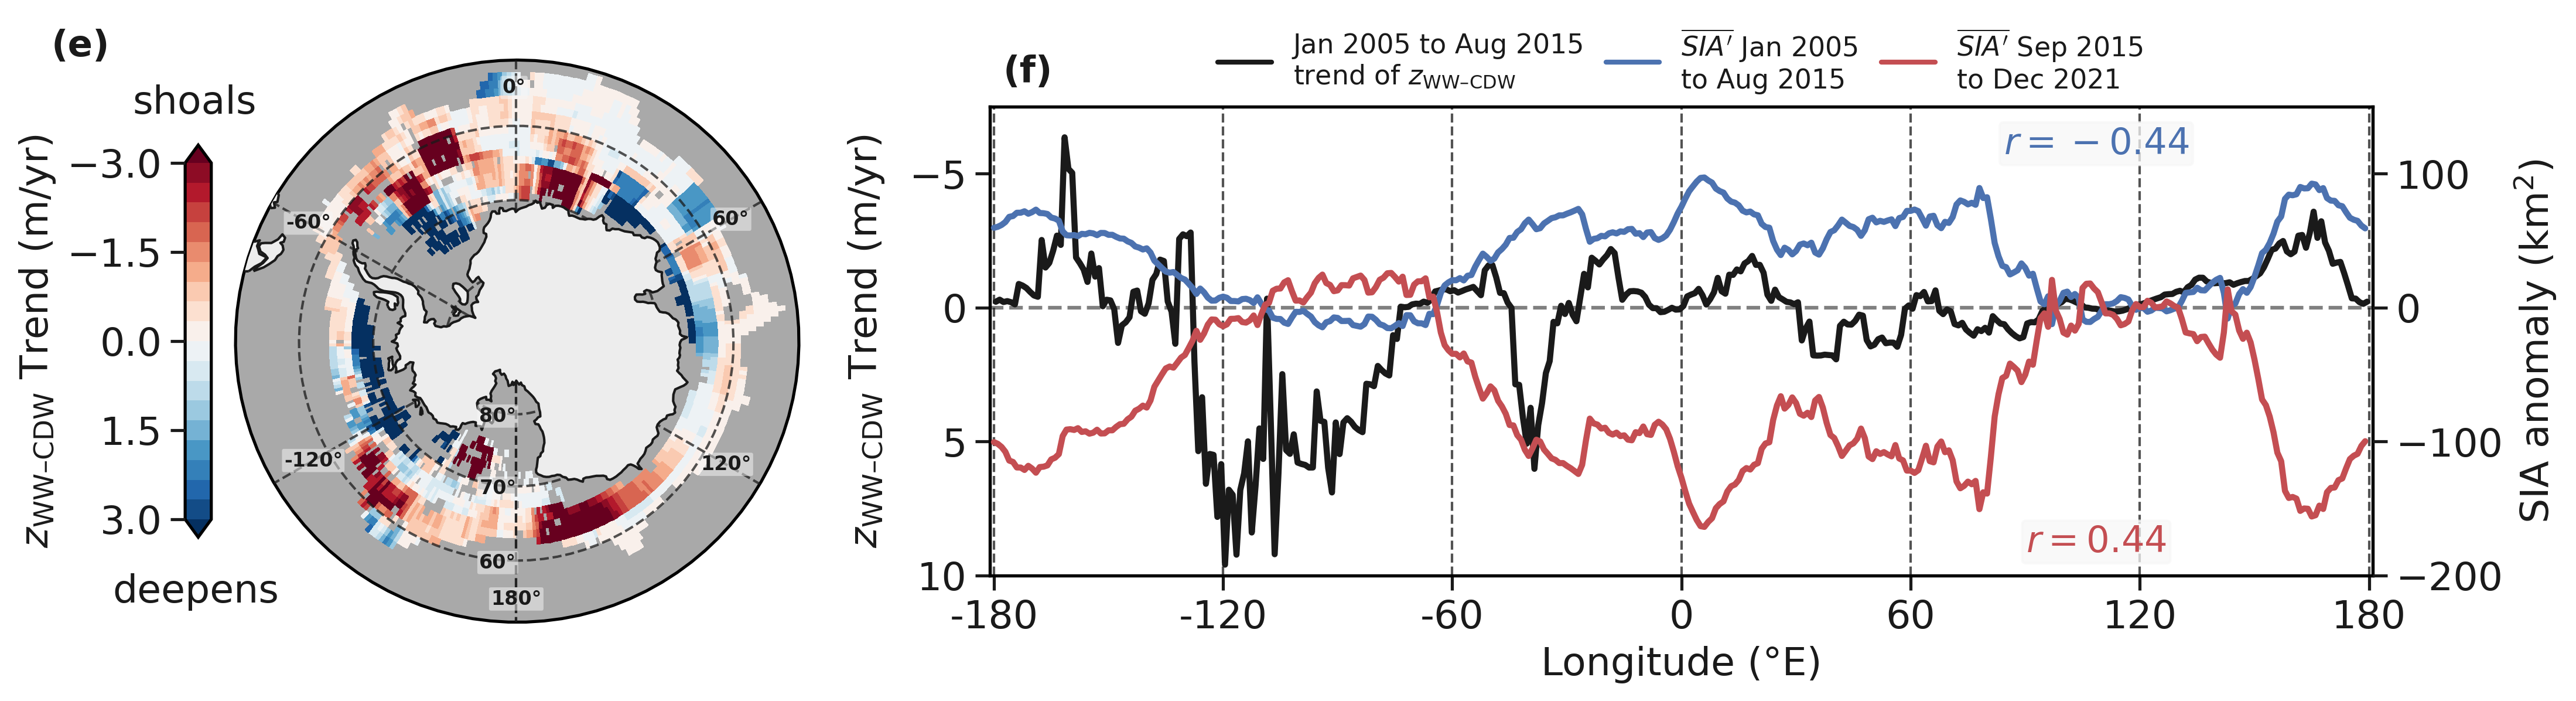

In [21]:
save_fig = 1

# compute trends for var
var = 'lw_bd'
units = 'm'

vmax = 3
vmin,vmax = -vmax,vmax
nx,ny = 10,5

wrap_kw = dict(nx=nx,ny=ny,mp=1)


trend,n = calc_trend_per_gc(tmp[var])
# trend = trend*-1

#### compute correlation between var and SIA ####
da1 = compute_weighted_average(wrap_smth_var(trend,**wrap_kw),dims=('lat'))
#da2 = si.sia_anm.sel(time=t_slice_p1).mean(('time','lat'))
da2 = compute_weighted_average(si.sia_anm.sel(time=t_slice_p1),dims=('time','lat'))
da2['lon'] = da2['lon'] + 0.5
r_p1,p_p1 = compute_correlation(da1,da2,smoothed=nx)

# for second period
#da2 = si.sia_anm.sel(time=t_slice_p2).mean(('time','lat'))
da2 = compute_weighted_average(si.sia_anm.sel(time=t_slice_p2),dims=('time','lat'))
da2['lon'] = da2['lon'] + 0.5
r_p2,p_p2 = compute_correlation(da1,da2,smoothed=nx)

#### plotting ####
r,c = 1,2
fig = plt.figure(figsize=(15, 5), dpi=300)
gs = gridspec.GridSpec(3, 2, figure=fig, width_ratios=[4, 8], height_ratios=[0.05,10,0.05],)
crs = ccrs.PlateCarree()

# Create subplots for the first row (excluding the colorbar space)
ax = []

# Create subplots 
ax.append(fig.add_subplot(gs[:,0],projection=ccrs.SouthPolarStereo()))

# run for all axes
for i,a in enumerate(ax):
    circular_boundary(a)
    a.set_extent([0,360,-90,-51.5],crs=crs)
    a.add_feature(cfeature.LAND,zorder=9,facecolor="#ededed",)
    a.coastlines(zorder=10,color="k") # shows continental coastline
plot_gridlines(ax=ax[0],color='k',)    
ax[0].set_facecolor('darkgrey')

# vmax = 3
hmp = wrap_smth_var(trend,**wrap_kw).plot(ax=ax[0],x='lon',cmap=cmap_br.reversed(),vmin=-vmax,vmax=vmax,transform=crs, levels=19,
              cbar_kwargs={'label':'$z_{\\mathrm{WW\\text{–}CDW}}$ Trend 'f'({units}/yr)','shrink':1/2,'aspect':15,'pad':0.035,
                           'ticks':np.arange(vmin,vmax+.01,1.5),'location':'left'},)
hmp.colorbar.ax.invert_yaxis()
hmp.colorbar.ax.minorticks_off()
# Annotate colorbar with "deepens" and "shoals" in white, vertically
bbox_kw = dict(facecolor='#f7f7f7', edgecolor='#f7f7f7', boxstyle='round,pad=0.1', alpha=0.75)
ann_kw  = dict(xycoords='axes fraction', fontsize=16, ha='center', ) #bbox=bbox_kw)
ax[0].annotate("shoals", xy=(-0.0725, 0.905), color='k', **ann_kw, )
ax[0].annotate("deepens", xy=(-0.07, 0.035), color='k', **ann_kw, )

### second plot ###
ax.append(fig.add_subplot(gs[1,1]))

# plot the trend
lw = 2.5
#wrap_smth_var(trend,**wrap_kw).mean('lat'#).rolling({'lon':5},min_periods=1,center=1).mean(
compute_weighted_average(wrap_smth_var(trend,**wrap_kw),dims=('lat')
                        ).plot(x='lon',ax=ax[1],c='k',lw=lw,yincrease=1,zorder=10)
ax[1].set_xlim(-181,181)
ax[1].set_xticks(np.arange(-180,181,60),labels=np.arange(-180,181,60),)
ax[1].grid(which='major',axis='x',color='k',linestyle='--',linewidth=1,alpha=0.75)
ax[1].axhline(0,ls='--',c='grey',zorder=0)

# plot SIA for the two periods
tw_x = ax[1].twinx()
#si.sia_anm.sel(time=t_slice_p1).mean(('time','lat')).plot(x='lon',c='b',lw=lw,ax=tw_x,zorder=4)
#si.sia_anm.sel(time=t_slice_p2).mean(('time','lat')).plot(x='lon',c='r',lw=lw,ax=tw_x,zorder=4)
compute_weighted_average(si.sia_anm.sel(time=t_slice_p1),dims=('time','lat')).plot(x='lon',c='b',lw=lw,ax=tw_x,zorder=4)
compute_weighted_average(si.sia_anm.sel(time=t_slice_p2),dims=('time','lat')).plot(x='lon',c='r',lw=lw,ax=tw_x,zorder=4)


# annotate the correlation values
bbox_kw = dict(facecolor='#f7f7f7', edgecolor='#f7f7f7', boxstyle='round,pad=0.1', alpha=0.75)
ann_kw  = dict(xycoords='axes fraction', fontsize=15, ha='center', bbox=bbox_kw)
tw_x.annotate(f"$r={r_p1:.2f}$", xy=(0.8, 0.9), color='b', **ann_kw, )
tw_x.annotate(f"$r={r_p2:.2f}$", xy=(0.8, 0.05), color='r', **ann_kw, )
tw_x.set_ylabel('SIA anomaly (km$^2$)',)
tw_x.set_ylim(-200,200*3/4)

ax[1].set_ylim(-7.5,10)
ax[1].invert_yaxis()
ax[1].set_xlabel('Longitude (°E)',)
ax[1].set_ylabel('$z_{\\mathrm{WW\\text{–}CDW}}$ Trend (m/yr)',)
ax[1].yaxis.set_label_coords(-0.075, 0.5)

# add legend
ax[1].plot([],[],c='k',lw=2,label='Jan 2005 to Aug 2015\ntrend of $z_{\\mathrm{WW\\text{–}CDW}}$')
ax[1].plot([],[],c='b',lw=2,label='$\overline{SIA^\prime}$ Jan 2005 \nto Aug 2015')
ax[1].plot([],[],c='r',lw=2,label='$\overline{SIA^\prime}$ Sep 2015 \nto Dec 2021')
leg = ax[1].legend(loc='lower center', bbox_to_anchor=(0.5, .975), ncol=3, columnspacing=0.8)
leg.get_frame().set_facecolor('none')
leg.get_frame().set_linewidth(0)

bbox_kw = dict(facecolor='#f7f7f7', edgecolor='None', boxstyle='round,pad=0.1',alpha=0.5,)
ann_kw  = dict(transform=crs,zorder=100,fontsize=8,weight='bold',bbox=bbox_kw)
for lat in [-80,-70,-60]:
    ax[0].annotate(str(lat)[1:]+'°',xy=(-180,lat+0.25),ha='right',va='center',**ann_kw)
# add longitude labels
for lon,lat in zip([-0.5,-60,-120,180,120,60],[-55,-57,-57.75,-55,-56.75,-56]):
    ax[0].annotate(str(int(lon))+'°',xy=(lon,lat),ha='center',va='center',**ann_kw)

fig.tight_layout()
a_y = 1.1 # y pos'n
fig_labels(a_x=-0.275,a_y=1.025,ax=ax[0],j=4,add_bbox=0)
fig_labels(a_x=0.0275,a_y=1.075,ax=ax[1],j=5,add_bbox=0)

fig.tight_layout()

#ax[0].set_title('Trend of CDW upper\nboundary (2005–2015)')
#ax[1].set_title('CDW upper boundary trends and sea ice area',fontsize=15)

if save_fig:
    save_figure(fig=fig,figure_name='CDW_trend_SIA_corr.svg',save_fig=save_fig)

print('correlation between SIA´ p1 and trend:',r_p1,' p-value:',p_p1)
print('correlation between SIA´ p2 and trend:',r_p2,' p-value:',p_p2)